In [1]:
from pathlib import Path

# Path to our raw dataset
RAW_DATA_PATH = Path("../data/raw")

# Get all CSV files
csv_files = sorted(RAW_DATA_PATH.glob("*.csv"))

print("Number of CSV files:", len(csv_files))
print("\nCSV files:")

for file in csv_files:
    print("-", file.name)

Number of CSV files: 8

CSV files:
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
- Friday-WorkingHours-Morning.pcap_ISCX.csv
- Monday-WorkingHours.pcap_ISCX.csv
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
- Tuesday-WorkingHours.pcap_ISCX.csv
- Wednesday-workingHours.pcap_ISCX.csv


In [2]:
import pandas as pd

# Take the first CSV file
sample_file = csv_files[0]

# Load only the first 5 rows
sample_df = pd.read_csv(sample_file, nrows=5)

print("File:", sample_file.name)
print("Number of columns:", len(sample_df.columns))

print("\nColumns:")
for i, column in enumerate(sample_df.columns, start=1):
    print(f"{i}. {column}")

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of columns: 79

Columns:
1.  Destination Port
2.  Flow Duration
3.  Total Fwd Packets
4.  Total Backward Packets
5. Total Length of Fwd Packets
6.  Total Length of Bwd Packets
7.  Fwd Packet Length Max
8.  Fwd Packet Length Min
9.  Fwd Packet Length Mean
10.  Fwd Packet Length Std
11. Bwd Packet Length Max
12.  Bwd Packet Length Min
13.  Bwd Packet Length Mean
14.  Bwd Packet Length Std
15. Flow Bytes/s
16.  Flow Packets/s
17.  Flow IAT Mean
18.  Flow IAT Std
19.  Flow IAT Max
20.  Flow IAT Min
21. Fwd IAT Total
22.  Fwd IAT Mean
23.  Fwd IAT Std
24.  Fwd IAT Max
25.  Fwd IAT Min
26. Bwd IAT Total
27.  Bwd IAT Mean
28.  Bwd IAT Std
29.  Bwd IAT Max
30.  Bwd IAT Min
31. Fwd PSH Flags
32.  Bwd PSH Flags
33.  Fwd URG Flags
34.  Bwd URG Flags
35.  Fwd Header Length
36.  Bwd Header Length
37. Fwd Packets/s
38.  Bwd Packets/s
39.  Min Packet Length
40.  Max Packet Length
41.  Packet Length Mean
42.  Packet Length Std
43.  Packet L

In [5]:
for file in csv_files:
    # Read only the header
    columns = pd.read_csv(file, nrows=0).columns

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Last 5 columns:")

    for column in columns[-5:]:
        print(repr(column))


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Monday-WorkingHours.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Tuesday-WorkingHours.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

FILE: Wednesday-workingHours.pcap_ISCX.csv
Last 5 columns:
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' La

In [6]:
for file in csv_files:
    df = pd.read_csv(file, usecols=[" Label"])

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Number of rows:", len(df))

    print("\nLabels:")
    print(df[" Label"].value_counts())


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of rows: 225745

Labels:
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of rows: 286467

Labels:
 Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of rows: 191033

Labels:
 Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

FILE: Monday-WorkingHours.pcap_ISCX.csv
Number of rows: 529918

Labels:
 Label
BENIGN    529918
Name: count, dtype: int64

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Number of rows: 288602

Labels:
 Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Number of rows: 170366

Labels:
 Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Inje

In [7]:
# Store label counts from every CSV
label_counts = {}

total_rows = 0

for file in csv_files:
    df = pd.read_csv(file, usecols=[" Label"])

    total_rows += len(df)

    for label, count in df[" Label"].value_counts().items():
        label_counts[label] = label_counts.get(label, 0) + count

# Convert to Series and sort
overall_labels = pd.Series(label_counts).sort_values(ascending=False)

print("Total rows across all files:", total_rows)

print("\nOverall Label Distribution:")
print(overall_labels)

Total rows across all files: 2830743

Overall Label Distribution:
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
dtype: int64


In [8]:
benign_count = overall_labels.get("BENIGN", 0)

attack_count = total_rows - benign_count

benign_percentage = (benign_count / total_rows) * 100
attack_percentage = (attack_count / total_rows) * 100

print("BENIGN records :", benign_count)
print("ATTACK records :", attack_count)

print(f"\nBENIGN percentage : {benign_percentage:.2f}%")
print(f"ATTACK percentage : {attack_percentage:.2f}%")

BENIGN records : 2273097
ATTACK records : 557646

BENIGN percentage : 80.30%
ATTACK percentage : 19.70%


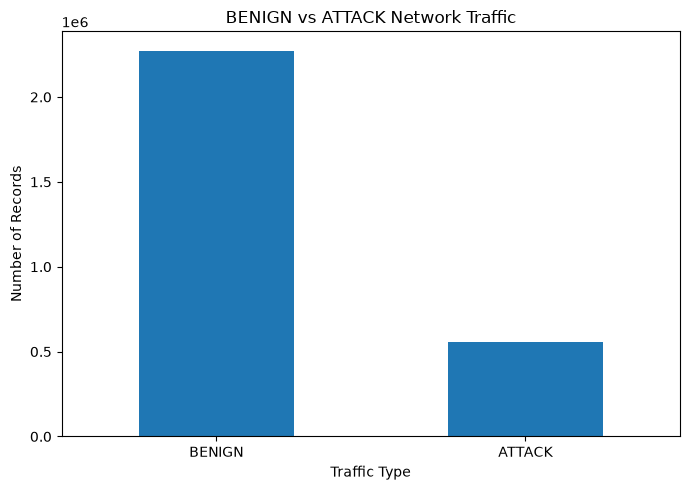

In [9]:
import matplotlib.pyplot as plt

# Create binary categories
binary_labels = pd.Series({
    "BENIGN": benign_count,
    "ATTACK": attack_count
})

# Plot
plt.figure(figsize=(7, 5))

binary_labels.plot(kind="bar")

plt.title("BENIGN vs ATTACK Network Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

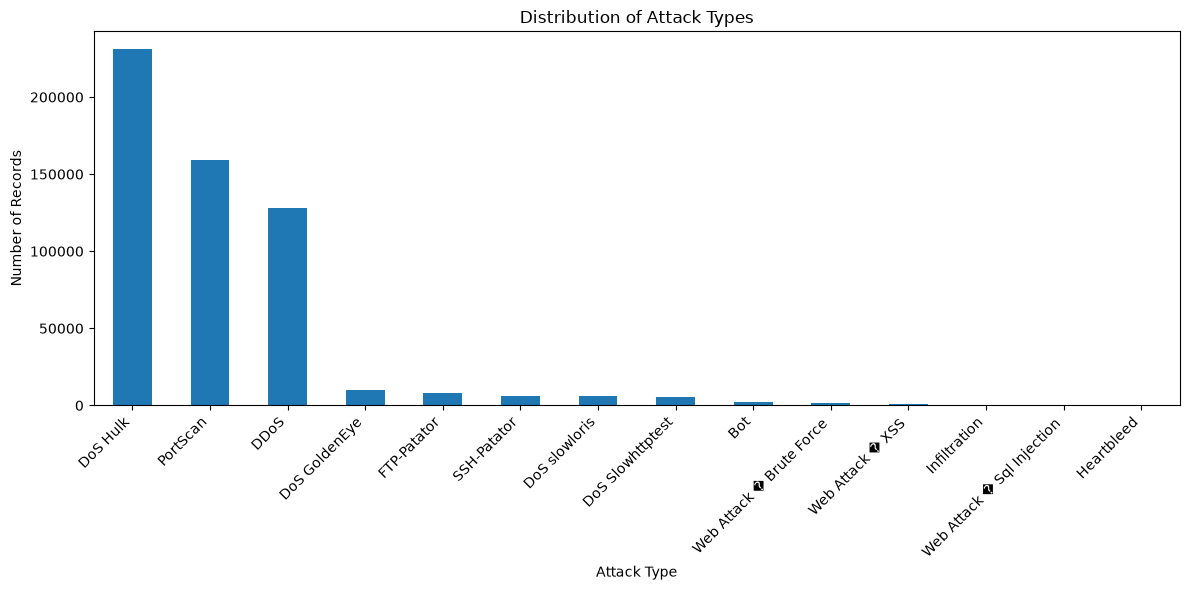

In [10]:
# Remove BENIGN so we can focus only on attacks
attack_labels = overall_labels.drop("BENIGN")

# Plot attack distribution
plt.figure(figsize=(12, 6))

attack_labels.plot(kind="bar")

plt.title("Distribution of Attack Types")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

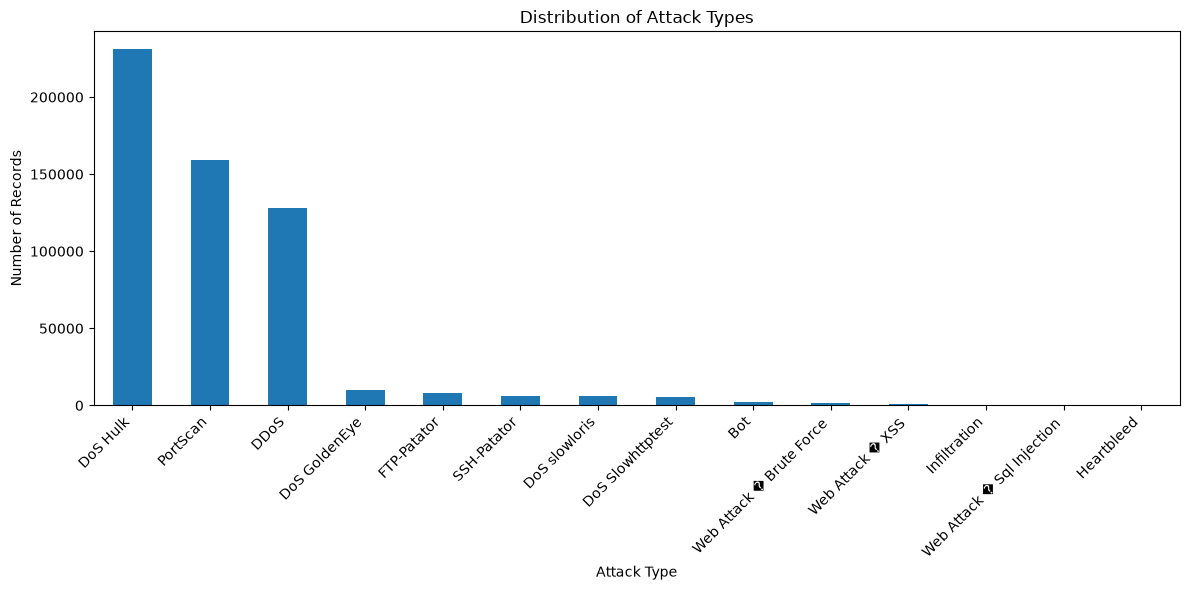

Figure saved to: ..\results\figures\attack_distribution.png


In [11]:
from pathlib import Path

# Create the figures folder if it doesn't exist
FIGURES_PATH = Path("../results/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# Create and save the attack distribution figure
plt.figure(figsize=(12, 6))

attack_labels.plot(kind="bar")

plt.title("Distribution of Attack Types")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save the figure
output_file = FIGURES_PATH / "attack_distribution.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", output_file)

In [12]:
# Check missing values in all CSV files

missing_summary = {}

for file in csv_files:
    df = pd.read_csv(file, nrows=10000)

    # Remove leading/trailing spaces only for checking column names
    df.columns = df.columns.str.strip()

    missing = df.isnull().sum()

    missing_summary[file.name] = missing.sum()

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Total missing values in first 10,000 rows:", missing.sum())

print("\n" + "=" * 70)
print("Missing-value summary:")
for file, count in missing_summary.items():
    print(f"{file}: {count}")


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total missing values in first 10,000 rows: 1

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total missing values in first 10,000 rows: 0

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Total missing values in first 10,000 rows: 0

FILE: Monday-WorkingHours.pcap_ISCX.csv
Total missing values in first 10,000 rows: 1

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Total missing values in first 10,000 rows: 0

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total missing values in first 10,000 rows: 2

FILE: Tuesday-WorkingHours.pcap_ISCX.csv
Total missing values in first 10,000 rows: 10

FILE: Wednesday-workingHours.pcap_ISCX.csv
Total missing values in first 10,000 rows: 4

Missing-value summary:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 1
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 0
Friday-WorkingHours-Morning.pcap_ISCX.csv: 0
Monday-WorkingHours.pcap_ISCX.csv: 1
Thur

In [13]:
# Check for infinite values in all CSV files

infinity_summary = {}

for file in csv_files:
    infinite_count = 0

    # Read the file in chunks
    for chunk in pd.read_csv(file, chunksize=50000):
        
        # Strip spaces from column names temporarily
        chunk.columns = chunk.columns.str.strip()

        # Check numeric columns for +inf and -inf
        numeric_data = chunk.select_dtypes(include="number")
        infinite_count += numeric_data.isin([float("inf"), float("-inf")]).sum().sum()

    infinity_summary[file.name] = infinite_count

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Infinite values:", infinite_count)

print("\n" + "=" * 70)
print("Overall infinite-value summary:")

total_infinite = sum(infinity_summary.values())

for file, count in infinity_summary.items():
    print(f"{file}: {count}")

print("\nTotal infinite values:", total_infinite)


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Infinite values: 64

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Infinite values: 727

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Infinite values: 216

FILE: Monday-WorkingHours.pcap_ISCX.csv
Infinite values: 810

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Infinite values: 396

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Infinite values: 250

FILE: Tuesday-WorkingHours.pcap_ISCX.csv
Infinite values: 327

FILE: Wednesday-workingHours.pcap_ISCX.csv
Infinite values: 1586

Overall infinite-value summary:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 64
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 727
Friday-WorkingHours-Morning.pcap_ISCX.csv: 216
Monday-WorkingHours.pcap_ISCX.csv: 810
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 396
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 250
Tuesday-WorkingHours.pcap_ISCX.csv: 327
Wednesday-workin

In [14]:
# Check duplicate rows in all CSV files

duplicate_summary = {}

for file in csv_files:
    duplicate_count = 0

    # Read the file in chunks
    for chunk in pd.read_csv(file, chunksize=50000):
        
        # Strip spaces from column names
        chunk.columns = chunk.columns.str.strip()

        # Count duplicate rows within each chunk
        duplicate_count += chunk.duplicated().sum()

    duplicate_summary[file.name] = duplicate_count

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Duplicate rows:", duplicate_count)

print("\n" + "=" * 70)
print("Overall duplicate-value summary:")

total_duplicates = sum(duplicate_summary.values())

for file, count in duplicate_summary.items():
    print(f"{file}: {count}")

print("\nTotal duplicate rows:", total_duplicates)


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Duplicate rows: 1572

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Duplicate rows: 44765

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Duplicate rows: 4471

FILE: Monday-WorkingHours.pcap_ISCX.csv
Duplicate rows: 14361

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Duplicate rows: 23236

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Duplicate rows: 3727

FILE: Tuesday-WorkingHours.pcap_ISCX.csv
Duplicate rows: 13894

FILE: Wednesday-workingHours.pcap_ISCX.csv
Duplicate rows: 67940

Overall duplicate-value summary:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 1572
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 44765
Friday-WorkingHours-Morning.pcap_ISCX.csv: 4471
Monday-WorkingHours.pcap_ISCX.csv: 14361
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 23236
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 3727
Tuesday-WorkingHours.pcap_ISCX.csv: 1389

In [15]:
# Check data types of the dataset

sample_df = pd.read_csv(csv_files[0], nrows=10000)

# Remove extra spaces from column names
sample_df.columns = sample_df.columns.str.strip()

print("Data types of all columns:\n")
print(sample_df.dtypes)

print("\n" + "=" * 70)

# Count each data type
print("Data type summary:")
print(sample_df.dtypes.value_counts())

Data types of all columns:

Destination Port                 int64
Flow Duration                    int64
Total Fwd Packets                int64
Total Backward Packets           int64
Total Length of Fwd Packets      int64
                                ...   
Idle Mean                      float64
Idle Std                       float64
Idle Max                         int64
Idle Min                         int64
Label                              str
Length: 79, dtype: object

Data type summary:
int64      54
float64    24
str         1
Name: count, dtype: int64


In [16]:
# Check for columns with only one unique value

constant_columns = []

for column in sample_df.columns:
    if sample_df[column].nunique() <= 1:
        constant_columns.append(column)

print("Number of constant columns:", len(constant_columns))

if constant_columns:
    print("\nConstant columns:")
    for column in constant_columns:
        print("-", column)
else:
    print("\nNo constant columns found.")

Number of constant columns: 11

Constant columns:
- Bwd PSH Flags
- Fwd URG Flags
- Bwd URG Flags
- CWE Flag Count
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate
- Label


In [17]:
# Calculate percentage distribution of every class

label_percentage = (overall_labels / total_rows) * 100

print("Class Distribution (%):\n")

for label, percentage in label_percentage.items():
    print(f"{label:<30} {percentage:.2f}%")

Class Distribution (%):

BENIGN                         80.30%
DoS Hulk                       8.16%
PortScan                       5.61%
DDoS                           4.52%
DoS GoldenEye                  0.36%
FTP-Patator                    0.28%
SSH-Patator                    0.21%
DoS slowloris                  0.20%
DoS Slowhttptest               0.19%
Bot                            0.07%
Web Attack � Brute Force       0.05%
Web Attack � XSS               0.02%
Infiltration                   0.00%
Web Attack � Sql Injection     0.00%
Heartbleed                     0.00%


In [18]:
# Check highly correlated numerical features

# Select only numerical columns
numeric_df = sample_df.select_dtypes(include=["int64", "float64"])

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Find feature pairs with correlation greater than 0.90
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        
        correlation_value = correlation_matrix.iloc[i, j]
        
        if abs(correlation_value) > 0.90:
            high_correlations.append(
                (
                    correlation_matrix.columns[i],
                    correlation_matrix.columns[j],
                    correlation_value
                )
            )

print("Number of highly correlated feature pairs:", len(high_correlations))

print("\nHighly correlated feature pairs:\n")

for feature1, feature2, correlation in high_correlations:
    print(f"{feature1} <--> {feature2} : {correlation:.3f}")

Number of highly correlated feature pairs: 93

Highly correlated feature pairs:

Flow Duration <--> Fwd IAT Total : 0.999
Flow Duration <--> Bwd IAT Total : 0.989
Total Fwd Packets <--> Total Backward Packets : 0.974
Total Fwd Packets <--> Total Length of Bwd Packets : 0.944
Total Fwd Packets <--> Fwd Header Length : 0.976
Total Fwd Packets <--> Bwd Header Length : 0.937
Total Fwd Packets <--> Fwd Header Length.1 : 0.976
Total Fwd Packets <--> Subflow Fwd Packets : 1.000
Total Fwd Packets <--> Subflow Bwd Packets : 0.974
Total Fwd Packets <--> Subflow Bwd Bytes : 0.944
Total Fwd Packets <--> act_data_pkt_fwd : 0.917
Total Backward Packets <--> Total Length of Bwd Packets : 0.971
Total Backward Packets <--> Fwd Header Length : 0.970
Total Backward Packets <--> Bwd Header Length : 0.973
Total Backward Packets <--> Fwd Header Length.1 : 0.970
Total Backward Packets <--> Subflow Fwd Packets : 0.974
Total Backward Packets <--> Subflow Bwd Packets : 1.000
Total Backward Packets <--> Subflow 

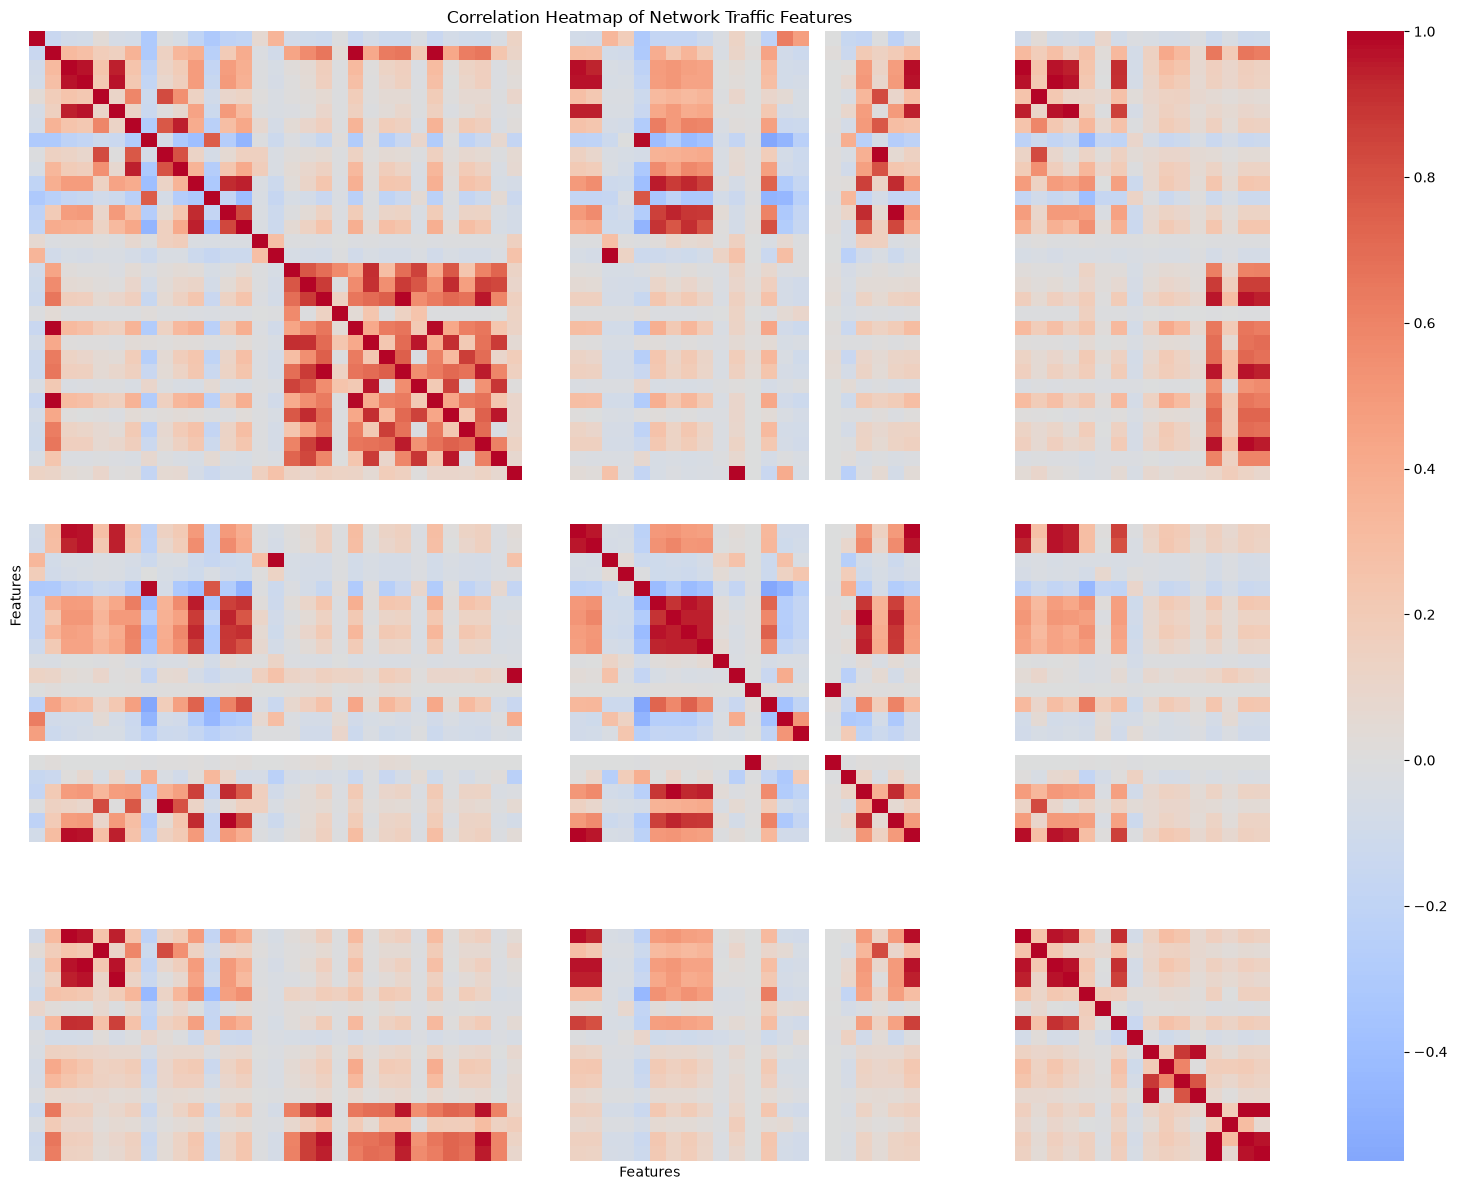

Figure saved to: ..\results\figures\correlation_heatmap.png


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create correlation heatmap

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Heatmap of Network Traffic Features")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()

# Save the figure
output_file = FIGURES_PATH / "correlation_heatmap.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", output_file)

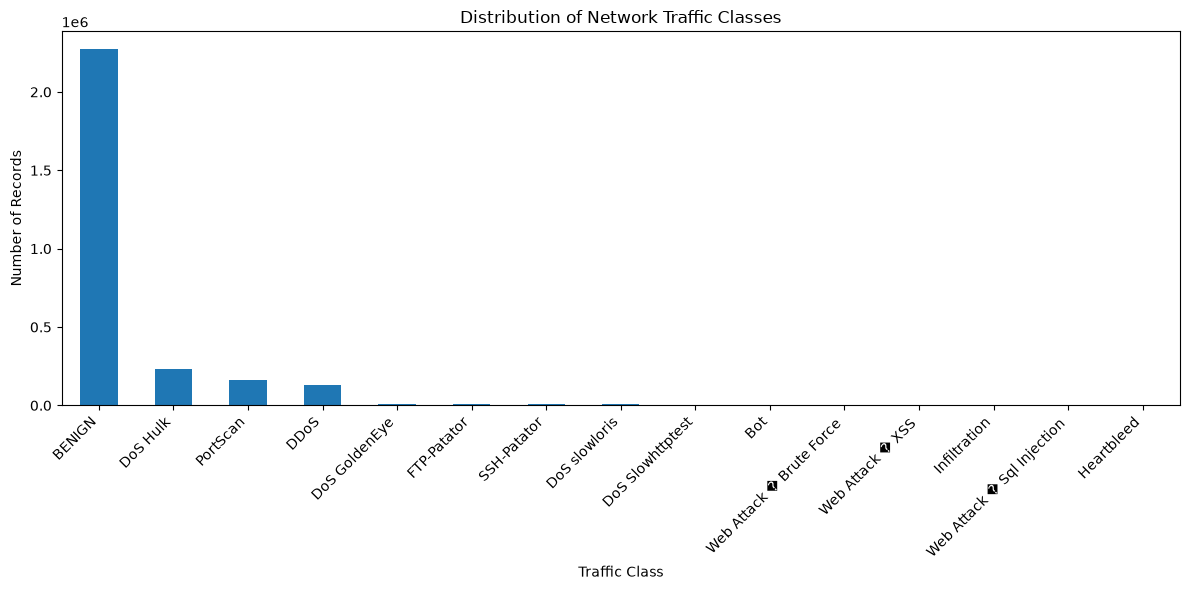

Figure saved to: ..\results\figures\class_distribution.png


In [21]:
# Plot class distribution

plt.figure(figsize=(12, 6))

overall_labels.plot(kind="bar")

plt.title("Distribution of Network Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save the figure
output_file = FIGURES_PATH / "class_distribution.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", output_file)

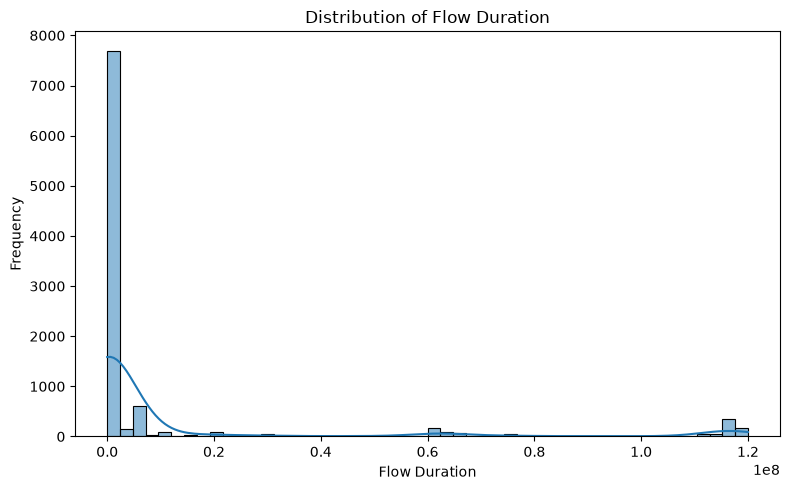

Saved: ..\results\figures\Flow_Duration_distribution.png


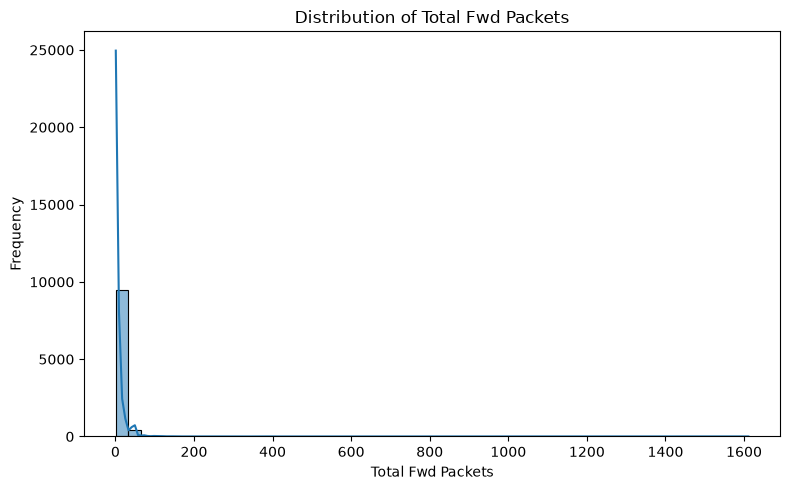

Saved: ..\results\figures\Total_Fwd_Packets_distribution.png


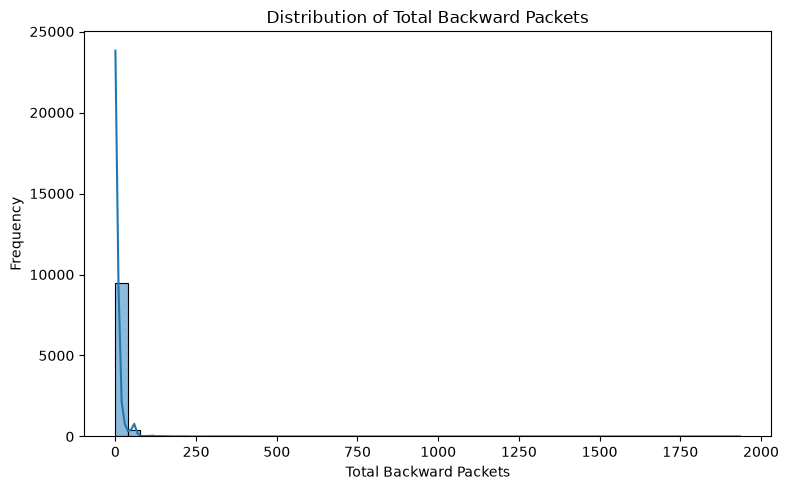

Saved: ..\results\figures\Total_Backward_Packets_distribution.png


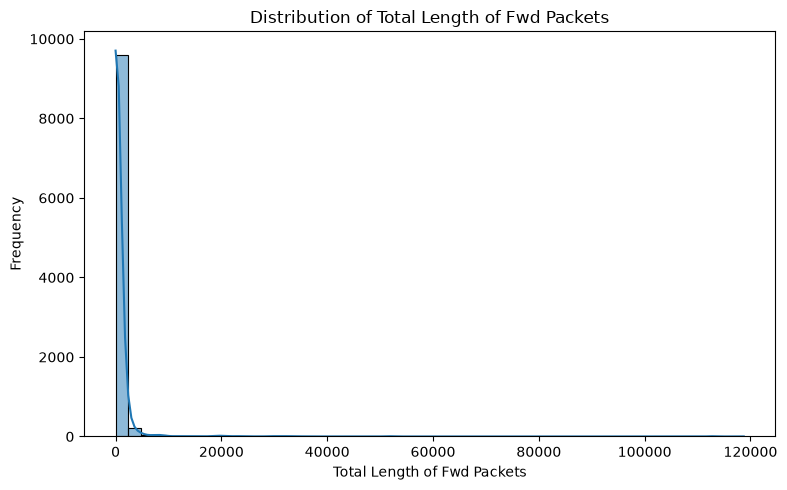

Saved: ..\results\figures\Total_Length_of_Fwd_Packets_distribution.png


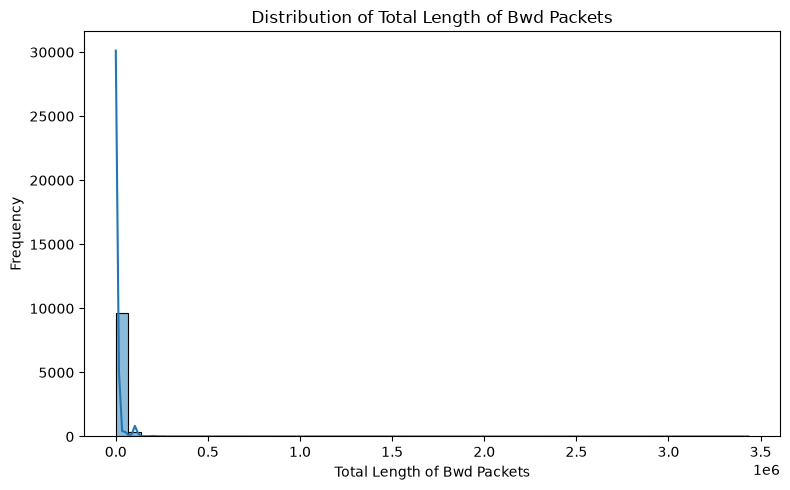

Saved: ..\results\figures\Total_Length_of_Bwd_Packets_distribution.png


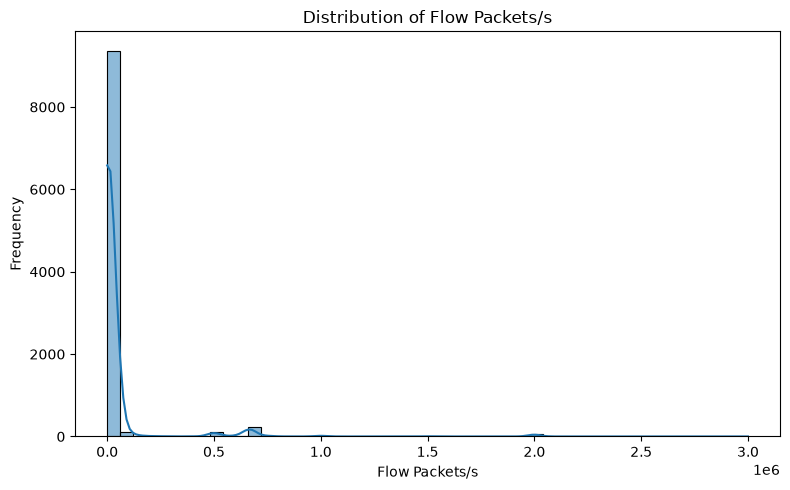

Saved: ..\results\figures\Flow_Packets_s_distribution.png


In [22]:
# Select important numerical features for distribution analysis

selected_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Packets/s"
]

# Create distribution plots
for feature in selected_features:
    
    plt.figure(figsize=(8, 5))
    
    sns.histplot(
        sample_df[feature],
        bins=50,
        kde=True
    )
    
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    
    # Create a safe filename
    safe_name = feature.replace("/", "_").replace(" ", "_")
    
    output_file = FIGURES_PATH / f"{safe_name}_distribution.png"
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    
    plt.show()
    
    print("Saved:", output_file)

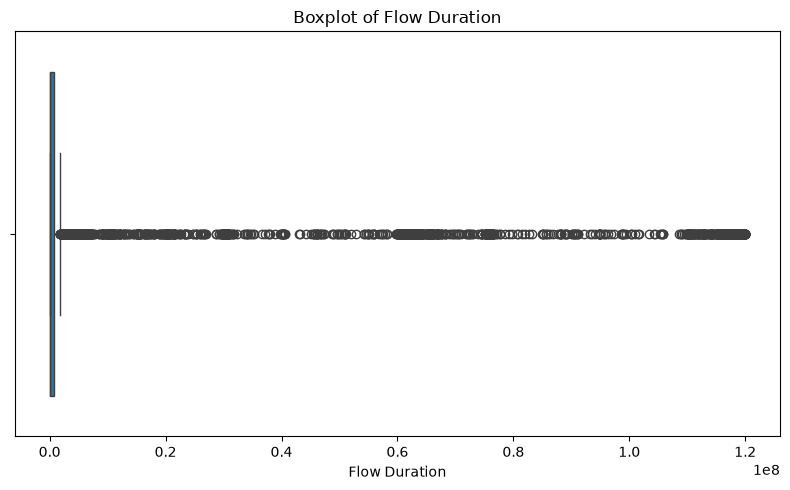

Saved: ..\results\figures\Flow_Duration_boxplot.png


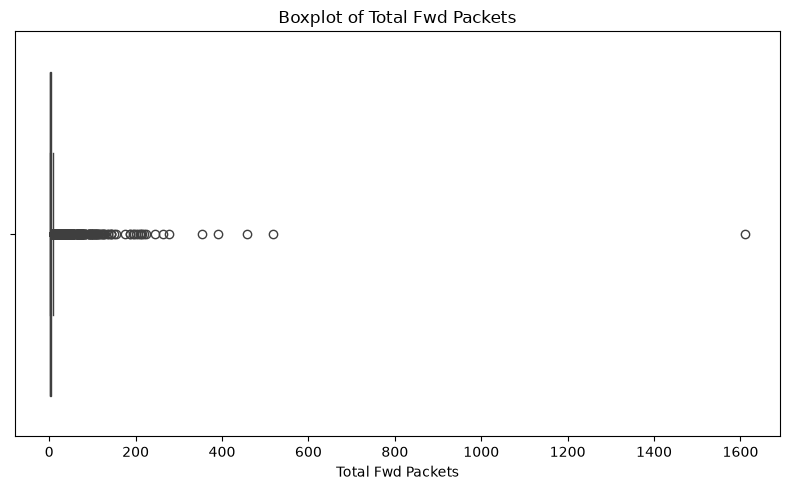

Saved: ..\results\figures\Total_Fwd_Packets_boxplot.png


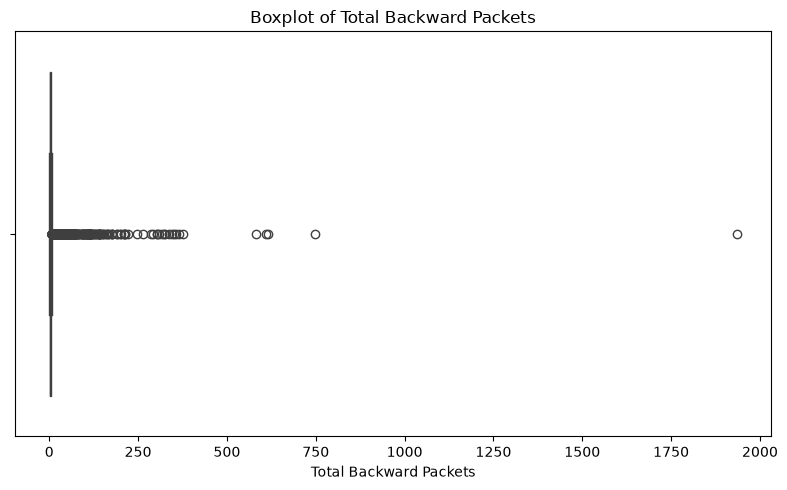

Saved: ..\results\figures\Total_Backward_Packets_boxplot.png


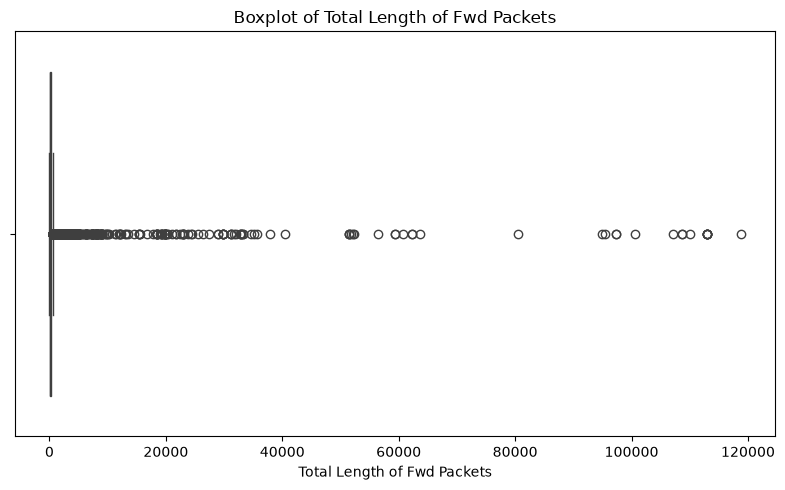

Saved: ..\results\figures\Total_Length_of_Fwd_Packets_boxplot.png


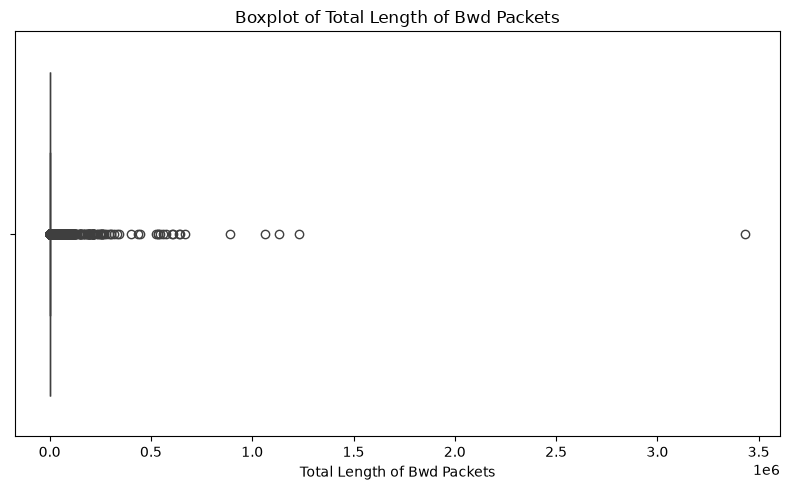

Saved: ..\results\figures\Total_Length_of_Bwd_Packets_boxplot.png


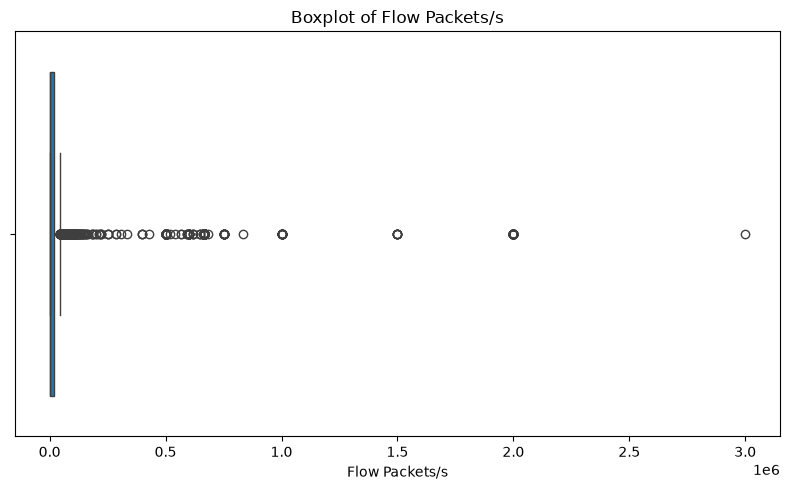

Saved: ..\results\figures\Flow_Packets_s_boxplot.png


In [24]:
# Select important features for outlier analysis

outlier_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Packets/s"
]

# Create boxplots
for feature in outlier_features:
    
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(x=sample_df[feature])
    
    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)
    
    plt.tight_layout()
    
    # Save the figure
    safe_name = feature.replace("/", "_").replace(" ", "_")
    output_file = FIGURES_PATH / f"{safe_name}_boxplot.png"
    
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    
    plt.show()
    
    print("Saved:", output_file)

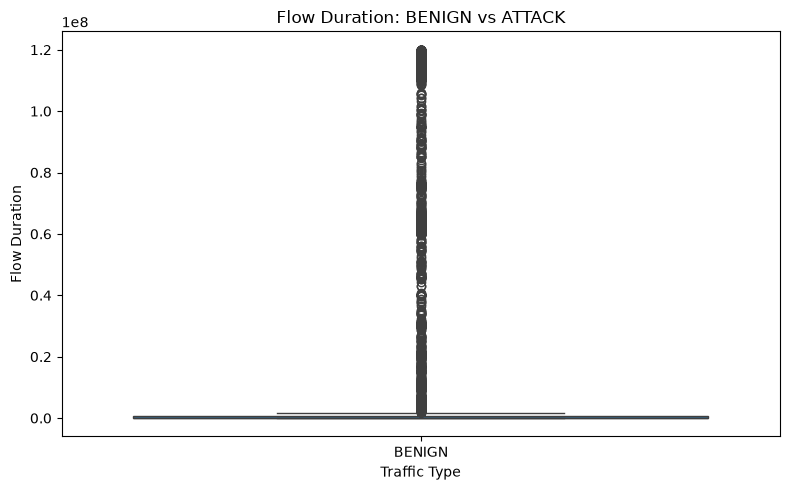

Saved: ..\results\figures\Flow_Duration_benign_vs_attack.png


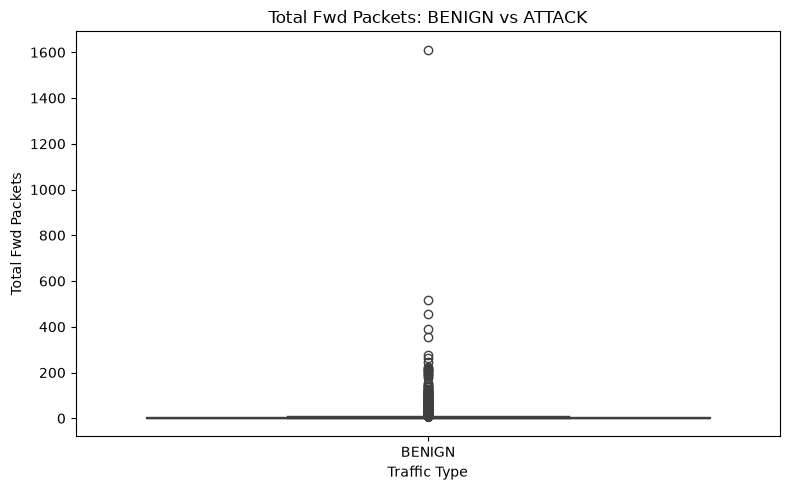

Saved: ..\results\figures\Total_Fwd_Packets_benign_vs_attack.png


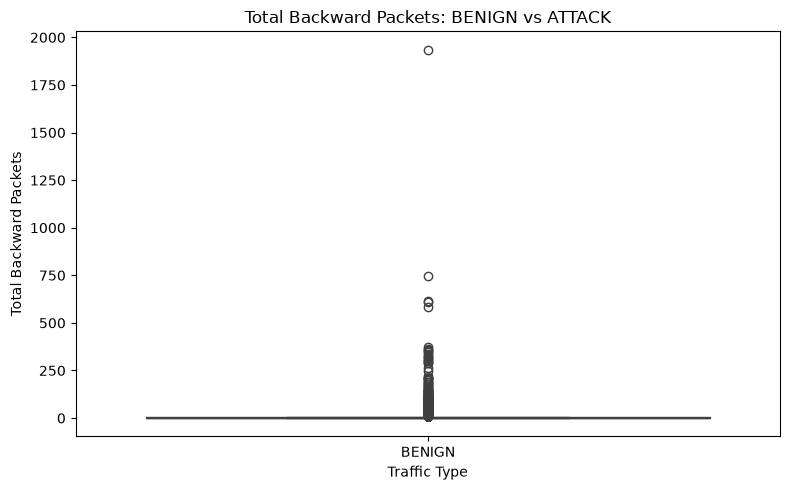

Saved: ..\results\figures\Total_Backward_Packets_benign_vs_attack.png


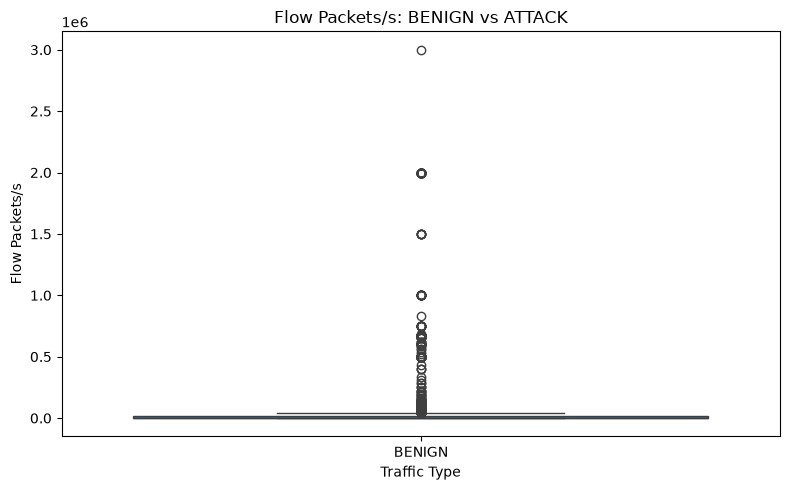

Saved: ..\results\figures\Flow_Packets_s_benign_vs_attack.png


In [25]:
# Create a binary traffic category
comparison_df = sample_df.copy()

comparison_df["Traffic Type"] = comparison_df["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

# Features to compare
comparison_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Packets/s"
]

# Create boxplots for each feature
for feature in comparison_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=comparison_df,
        x="Traffic Type",
        y=feature
    )

    plt.title(f"{feature}: BENIGN vs ATTACK")
    plt.xlabel("Traffic Type")
    plt.ylabel(feature)

    plt.tight_layout()

    # Save figure
    safe_name = feature.replace("/", "_").replace(" ", "_")
    output_file = FIGURES_PATH / f"{safe_name}_benign_vs_attack.png"

    plt.savefig(output_file, dpi=300, bbox_inches="tight")

    plt.show()

    print("Saved:", output_file)

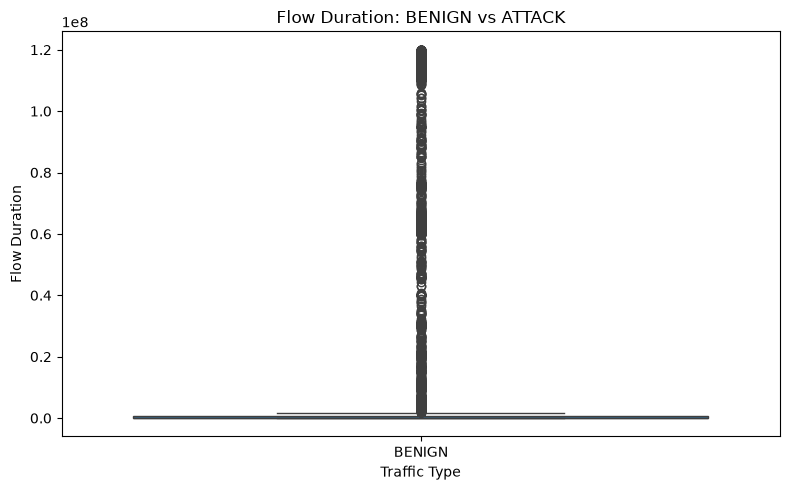

Saved: ..\results\figures\Flow_Duration_benign_vs_attack.png


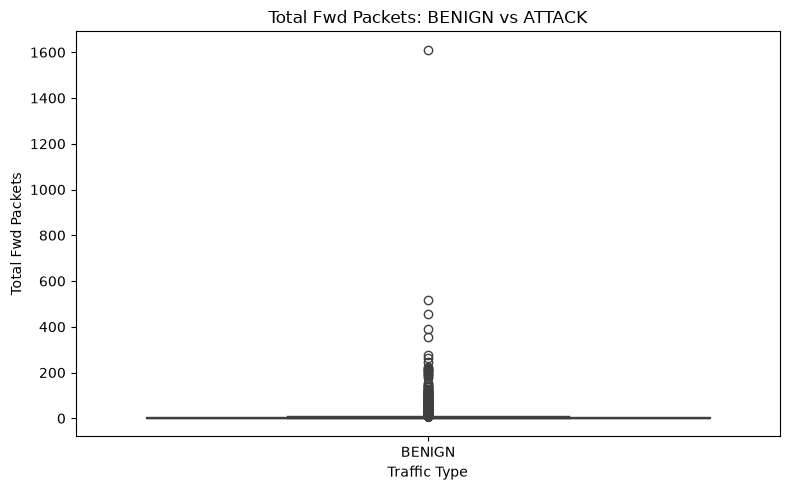

Saved: ..\results\figures\Total_Fwd_Packets_benign_vs_attack.png


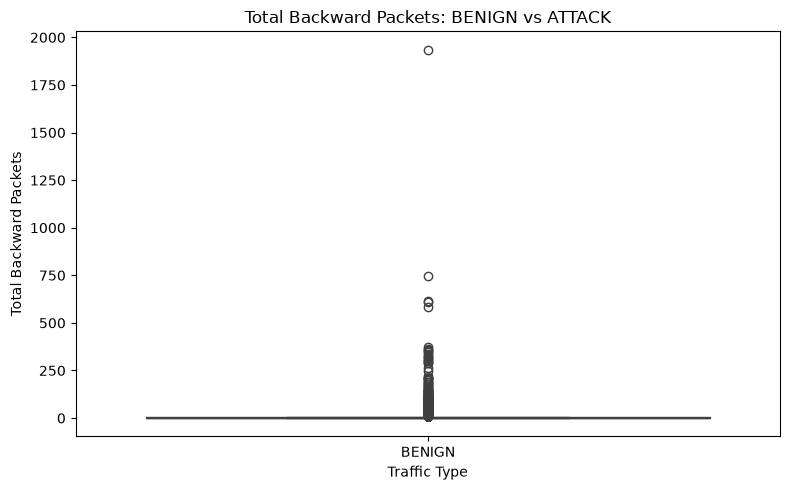

Saved: ..\results\figures\Total_Backward_Packets_benign_vs_attack.png


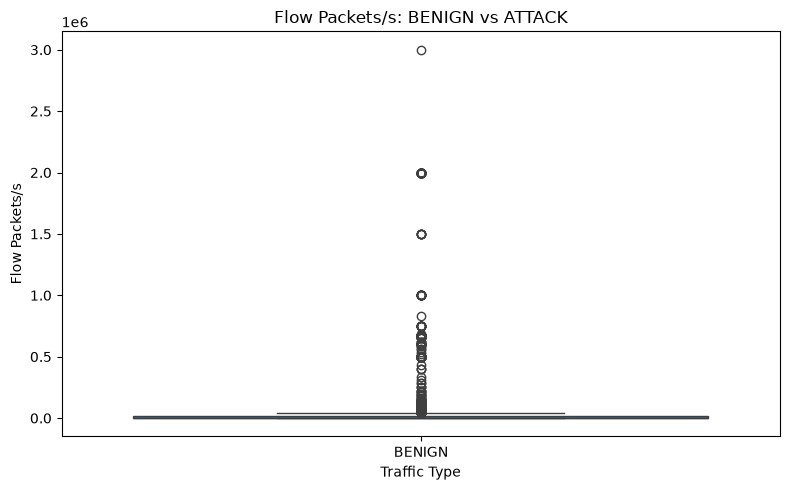

Saved: ..\results\figures\Flow_Packets_s_benign_vs_attack.png


In [26]:
# Create a binary traffic category
comparison_df = sample_df.copy()

comparison_df["Traffic Type"] = comparison_df["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

# Features to compare
comparison_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Packets/s"
]

# Create boxplots for each feature
for feature in comparison_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=comparison_df,
        x="Traffic Type",
        y=feature
    )

    plt.title(f"{feature}: BENIGN vs ATTACK")
    plt.xlabel("Traffic Type")
    plt.ylabel(feature)

    plt.tight_layout()

    # Save figure
    safe_name = feature.replace("/", "_").replace(" ", "_")
    output_file = FIGURES_PATH / f"{safe_name}_benign_vs_attack.png"

    plt.savefig(output_file, dpi=300, bbox_inches="tight")

    plt.show()

    print("Saved:", output_file)

In [27]:
# Statistical summary of numerical features

numeric_summary = sample_df.select_dtypes(
    include=["int64", "float64"]
).describe().T

# Add median separately
numeric_summary["median"] = sample_df.select_dtypes(
    include=["int64", "float64"]
).median()

# Display selected columns
numeric_summary = numeric_summary[
    ["count", "mean", "std", "min", "25%", "median", "75%", "max"]
]

print("Statistical Summary of Numerical Features:\n")

display(numeric_summary)

Statistical Summary of Numerical Features:



c:\Projects\CyberShield-AI\venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Projects\CyberShield-AI\venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,median,75%,max
Destination Port,10000.0,7.031618e+03,1.739600e+04,0.0,53.0,80.0,443.00,61463.0
Flow Duration,10000.0,1.197283e+07,3.102164e+07,0.0,210.0,47272.0,722121.25,119998109.0
Total Fwd Packets,10000.0,7.488800e+00,2.360219e+01,1.0,2.0,2.0,5.00,1611.0
Total Backward Packets,10000.0,7.782500e+00,3.082767e+01,0.0,1.0,2.0,4.00,1935.0
Total Length of Fwd Packets,10000.0,8.070068e+02,5.295267e+03,0.0,42.0,74.0,253.00,118736.0
...,...,...,...,...,...,...,...,...
Active Min,10000.0,6.485742e+04,1.211631e+06,0.0,0.0,0.0,0.00,100000000.0
Idle Mean,10000.0,3.557695e+06,1.246362e+07,0.0,0.0,0.0,0.00,120000000.0
Idle Std,10000.0,1.723737e+05,2.001759e+06,0.0,0.0,0.0,0.00,51000000.0
Idle Max,10000.0,3.689130e+06,1.284399e+07,0.0,0.0,0.0,0.00,120000000.0
